# Feature Engineering

This notebook builds the feature representations from the clean `int16` encoded traces which were created in the previous notebook. The following 4 representation will cover in this notebook:

1. **Frequency (bag of opcodes)** - How often each opcode appears it ignores order
2. **N-grams (bigram and trigram)** - Short local sequences it captures order
3. **Markov transition matrices** - Probability of one opcode following another
4. **Sliding-window phase vectors** - How the opcode mix changes over the run

All four are computed from the same encoded arrays so the raw text files are never touched again. Each representation is saved to features directory so the model development notebook can load them directly without recomputing the features.

*This project trains anomaly detection on **benign files only** so these features describe the benign behavioural baseline that the one-class models will later train from.*

## Setup the imports and paths

In [2]:
import sys
import os
import time
import json
import numpy as np
import pandas as pd
from scipy import sparse

sys.path.append("..")

from utils import (
    load_vocab,
    load_encoded_trace,
    opcode_frequency,
    opcode_entropy,
    ngram_counts,
    markov_transition_matrix,
    sliding_window_features,
)

In [3]:
ENCODED_DIR = "../sandbox/data-e4/encoded_traces"
CLEAN_VOCAB = "../sandbox/data/vocab_clean.json"
FEATURES_DIR = "../sandbox/data-e4/features"

# Make new directory for the features
os.makedirs(FEATURES_DIR, exist_ok=True)

# Load the clean vocab saved in the previous notebook
# This is the fixed feature space every representation uses the same ids
vocab = load_vocab(CLEAN_VOCAB)
vocab_size = len(vocab)
print(f"Clean Vocabulary Loaded: {vocab_size} opcodes")

# Collect all encoded trace files and sort so the row order stays consistent
npy_files = sorted([
    os.path.join(ENCODED_DIR, f)
    for f in os.listdir(ENCODED_DIR)
    if f.endswith(".npy")
])

print(f"Encoded trace files found: {len(npy_files)}")

# Filename (without extension) is the sample id used across every feature file
sample_ids = [os.path.basename(f).replace(".npy", "") for f in npy_files]

Clean Vocabulary Loaded: 287 opcodes
Encoded trace files found: 100


----
## 1. Frequency Features (Bag of Opcodes)

The simplest representation. For each file count how many times each opcode appears, then normalize into proportions so files of different lengths are comparable. This loses all sequence information but gives a compact for per file summary of the instruction mix.

In [4]:
freq_rows = []
entropy_rows = []

print(f"Building frequency features for {len(npy_files)} files...\n")
t0 = time.time()

for i, path in enumerate(npy_files, 1):
    # mmap keeps memory low, the array is read but not copied into RAM fully
    array = load_encoded_trace(path, mmap=True)

    # Raw counts per opcode id, then normalize to proportions (weights) 
    # So files of different lengths can be compared
    counts = opcode_frequency(array, vocab_size)
    total = counts.sum()
    weights = counts / total if total > 0 else counts

    freq_rows.append(weights)

    # Entropy is a single number per file and saved as a separate DataFrame
    entropy_rows.append(opcode_entropy(counts))

    if i % 20 == 0 or i == len(npy_files):
        print(f"  [{i:>3}/{len(npy_files)}]  elapsed: {(time.time()-t0)/60:.1f} min")

# Assemble into a DataFrame, columns named by the actual opcode strings
df_freq = pd.DataFrame(freq_rows, columns=vocab)
df_freq.insert(0, "sample_id", sample_ids)

print(f"\nFrequency feature matrix shape: {df_freq.shape}")

Building frequency features for 100 files...

  [ 20/100]  elapsed: 0.7 min
  [ 40/100]  elapsed: 1.3 min
  [ 60/100]  elapsed: 1.8 min
  [ 80/100]  elapsed: 2.4 min
  [100/100]  elapsed: 2.9 min

Frequency feature matrix shape: (100, 288)


In [5]:
# Entropy also saved as a separate DataFrame
df_entropy = pd.DataFrame({
    "sample_id": sample_ids,
    "opcode_entropy": entropy_rows,
})

print("Opcode entropy summary across all files:")
print(df_entropy["opcode_entropy"].describe())

Opcode entropy summary across all files:
count    100.000000
mean       4.182425
std        0.017806
min        4.106242
25%        4.174308
50%        4.184264
75%        4.189679
max        4.246225
Name: opcode_entropy, dtype: float64


In [6]:
df_freq.to_csv(os.path.join(FEATURES_DIR, "frequency_features.csv"), index=False)
df_entropy.to_csv(os.path.join(FEATURES_DIR, "opcode_entropy.csv"), index=False)

print("frequency_features.csv file saved!")
print("opcode_entropy.csv file saved!")

frequency_features.csv file saved!
opcode_entropy.csv file saved!


### Visualize the Frequency Features

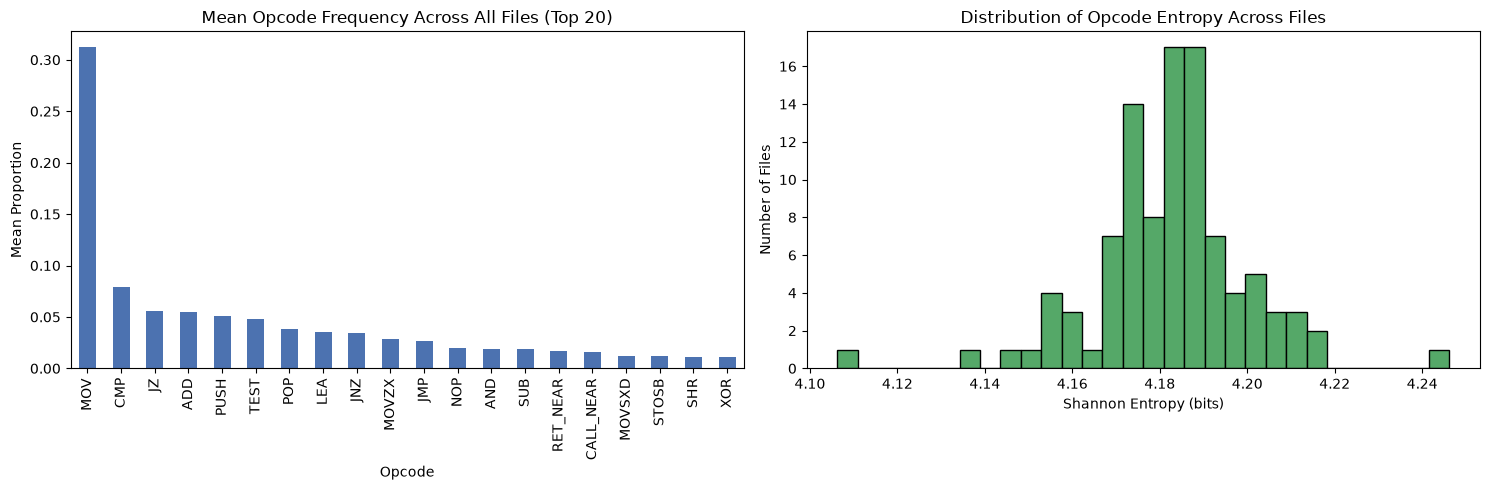

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1 - mean opcode frequency across all files which opcodes dominates
mean_freq = df_freq[vocab].mean().sort_values(ascending=False)
mean_freq.head(20).plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Mean Opcode Frequency Across All Files (Top 20)")
axes[0].set_ylabel("Mean Proportion")
axes[0].set_xlabel("Opcode")

# Plot 2 - distribution of opcode entropy per file
axes[1].hist(df_entropy["opcode_entropy"], bins=30, color="#55A868", edgecolor="black")
axes[1].set_title("Distribution of Opcode Entropy Across Files")
axes[1].set_xlabel("Shannon Entropy (bits)")
axes[1].set_ylabel("Number of Files")

plt.tight_layout()
plt.show()

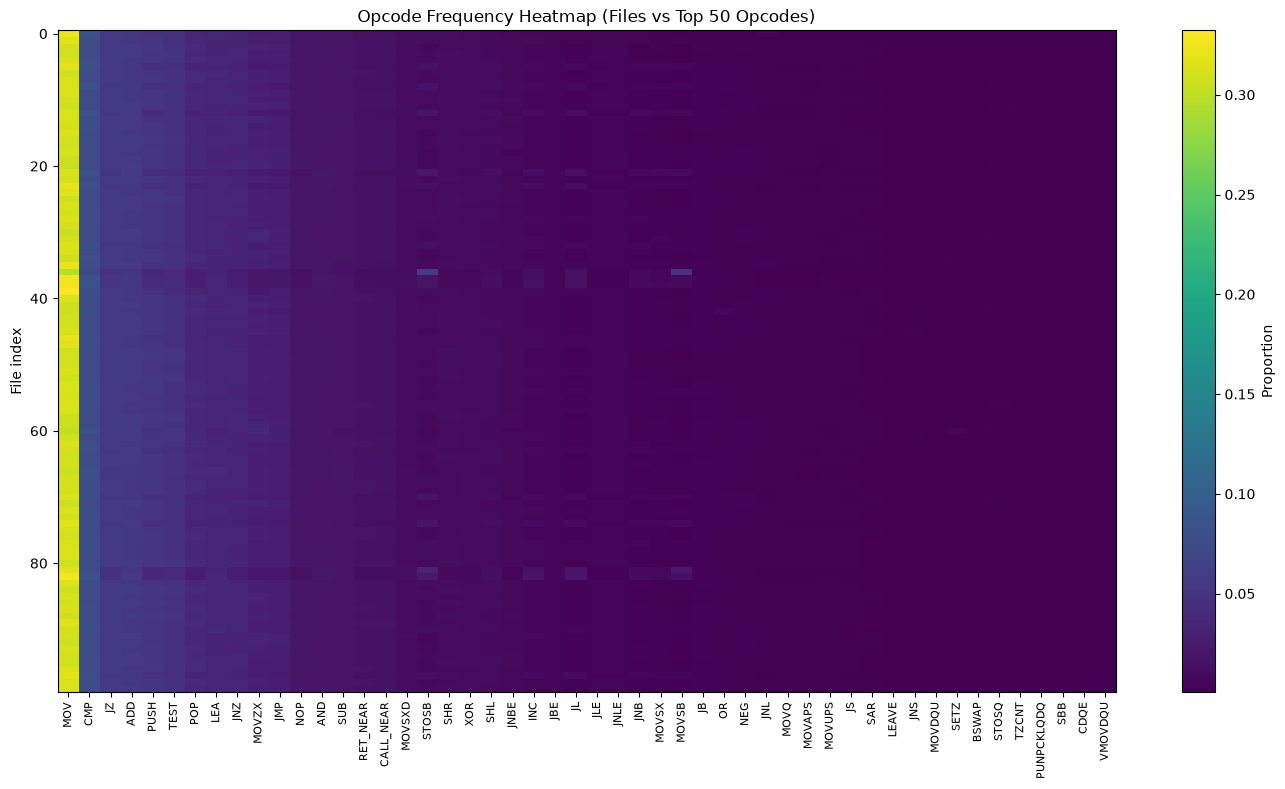

In [8]:
# Frequency heatmap - files against opcodes which shows behavioural grouping
# Only the top opcodes are shown so the axis stays readable for no more than 50 opcodes
top_opcodes = df_freq[vocab].mean().sort_values(ascending=False).head(50).index.tolist()

fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(df_freq[top_opcodes].values, aspect="auto", cmap="viridis")

ax.set_xticks(range(len(top_opcodes)))
ax.set_xticklabels(top_opcodes, rotation=90, fontsize=8)
ax.set_ylabel("File index")
ax.set_title("Opcode Frequency Heatmap (Files vs Top 50 Opcodes)")
fig.colorbar(im, ax=ax, label="Proportion")

plt.tight_layout()
plt.show()

----
## 2. N-gram Features (Bigram and Trigram)

N-grams capture short local sequences of opcodes. A bigram is a pair of consecutive opcodes, a trigram is three in a row.

**Dimensionality is important here** because the vocabulary size is 287, so the number of possible n-grams grows quickly.

- The bigram space has about 82,000 possible pairs - vocab_size squared
- The trigram space has around 23.6 million possible triples - vocab_size cubed

The bigram space is large but can be managed as a sparse matrix. The trigram space is too large to store completely, so in here, only going to keep the n-grams that actually appear using a sparse matrix (`scipy.sparse`). 

### Bigram features

For each file count every consecutive opcode pair. The result is stored as a sparse row so the around 82,000 column matrix does not waste memory on the many pairs that never occur.

In [9]:
bigram_dim = vocab_size ** 2
bigram_rows = []

print(f"Building Bigram Features: (dim = {bigram_dim:,}) for {len(npy_files)} files...\n")
t0 = time.time()

for i, path in enumerate(npy_files, 1):
    array = load_encoded_trace(path, mmap=True)

    # ngram_counts returns a flat dense array of length vocab_size**2
    # Convert to sparse immediately so only non-zero pairs are stored
    counts = ngram_counts(array, vocab_size, n=2)
    bigram_rows.append(sparse.csr_matrix(counts, dtype=np.int64))

    if i % 20 == 0 or i == len(npy_files):
        print(f"  [{i:>3}/{len(npy_files)}]  elapsed: {(time.time()-t0)/60:.1f} min")

# Stack all per-file sparse rows into one sparse matrix, one row per file
bigram_matrix = sparse.vstack(bigram_rows).tocsr()
print(f"\nBigram Sparse Matrix Shape: {bigram_matrix.shape}")
print(f"Stored Non-Zero Values: {bigram_matrix.nnz:,}")
print(f"Density: {bigram_matrix.nnz / (bigram_matrix.shape[0]*bigram_matrix.shape[1]) * 100:.4f}%")

Building Bigram Features: (dim = 82,369) for 100 files...

  [ 20/100]  elapsed: 1.5 min
  [ 40/100]  elapsed: 2.9 min
  [ 60/100]  elapsed: 4.0 min
  [ 80/100]  elapsed: 5.6 min
  [100/100]  elapsed: 7.0 min

Bigram Sparse Matrix Shape: (100, 82369)
Stored Non-Zero Values: 665,191
Density: 8.0757%


In [10]:
# Save the sparse bigram matrix + the sample id order it follows
sparse.save_npz(os.path.join(FEATURES_DIR, "bigram_features.npz"), bigram_matrix)

with open(os.path.join(FEATURES_DIR, "bigram_sample_ids.json"), "w") as f:
    json.dump(sample_ids, f, indent=2)

print("bigram_features.npz file saved!")
print("bigram_sample_ids.json file saved!")

bigram_features.npz file saved!
bigram_sample_ids.json file saved!


### Trigram Features

Same process as bigrams. The full trigram space is around 23.6 million columns, so the sparse form is important here, storing a dense row will be impossible. Only triples that actually appear are going to be stored. The result is a sparse matrix with the same number of rows as files and a column for each unique trigram that appears in the dataset.

In [11]:
trigram_dim = vocab_size ** 3
trigram_rows = []

print(f"Building Trigram Features (dim = {trigram_dim:,}) for {len(npy_files)} files...\n")
t0 = time.time()

for i, path in enumerate(npy_files, 1):
    array = load_encoded_trace(path, mmap=True)

    # For trigrams the flat dense array would be around 23.6M long
    # So build it and convert to sparse straight away which keeps only the non-zero triples
    counts = ngram_counts(array, vocab_size, n=3)
    trigram_rows.append(sparse.csr_matrix(counts, dtype=np.int64))

    if i % 20 == 0 or i == len(npy_files):
        print(f"  [{i:>3}/{len(npy_files)}]  elapsed: {(time.time()-t0)/60:.1f} min")

trigram_matrix = sparse.vstack(trigram_rows).tocsr()
print(f"\nTrigram Sparse Matrix Shape: {trigram_matrix.shape}")
print(f"Stored Non-Zero Values: {trigram_matrix.nnz:,}")
print(f"Density: {trigram_matrix.nnz / (trigram_matrix.shape[0]*trigram_matrix.shape[1]) * 100:.6f}%")

Building Trigram Features (dim = 23,639,903) for 100 files...

  [ 20/100]  elapsed: 2.1 min
  [ 40/100]  elapsed: 4.1 min
  [ 60/100]  elapsed: 5.6 min
  [ 80/100]  elapsed: 7.3 min
  [100/100]  elapsed: 8.8 min

Trigram Sparse Matrix Shape: (100, 23639903)
Stored Non-Zero Values: 5,349,544
Density: 0.226293%


In [12]:
sparse.save_npz(os.path.join(FEATURES_DIR, "trigram_features.npz"), trigram_matrix)
print("trigram_features.npz file saved!")
print("Trigram uses the same sample id order as bigram_sample_ids.json")

trigram_features.npz file saved!
Trigram uses the same sample id order as bigram_sample_ids.json


### Visualizing the N-gram Features

Plotting all 82,369 bigram pairs at once is not going to be possible so three targeted views are used instead.

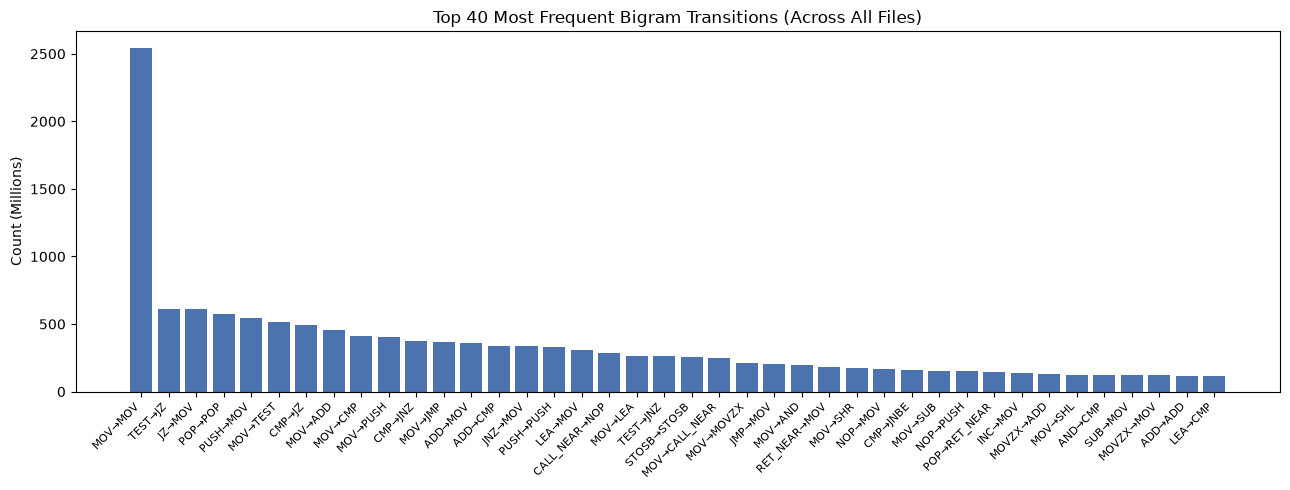

In [13]:
import matplotlib.pyplot as plt

# Rebuild the bigram matrix from the saved sparse matrix
# This is used for all three N-gram plots
bigram_agg = np.array(bigram_matrix.sum(axis=0)).flatten()
bigram_agg_2d = bigram_agg.reshape(vocab_size, vocab_size)

# Plot 1 - Top 40 most frequent bigram transitions across all files
top_n_bigrams = 40
top_idx = np.argsort(bigram_agg)[-top_n_bigrams:][::-1]
top_labels = [f"{vocab[i // vocab_size]}→{vocab[i % vocab_size]}" for i in top_idx]
top_values = bigram_agg[top_idx]

fig, ax = plt.subplots(figsize = (13, 5))
ax.bar(range(top_n_bigrams), top_values / 1e6, color="#4C72B0")
ax.set_xticks(range(top_n_bigrams))
ax.set_xticklabels(top_labels, rotation = 45, ha="right", fontsize = 8)
ax.set_title(f"Top {top_n_bigrams} Most Frequent Bigram Transitions (Across All Files)")
ax.set_ylabel("Count (Millions)")

plt.tight_layout()
plt.show()

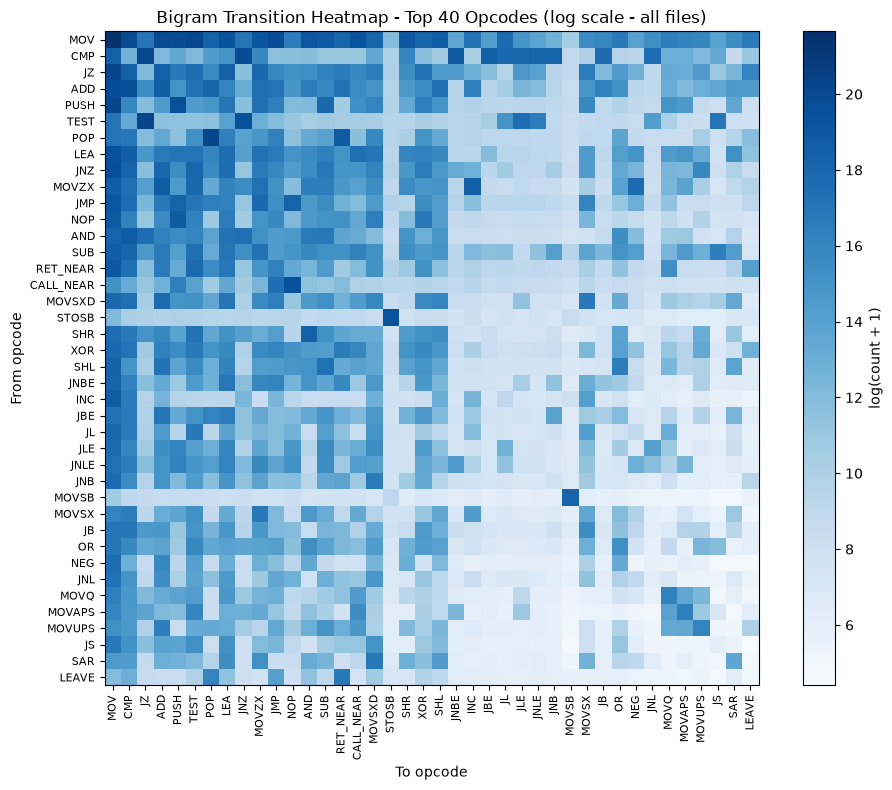

In [14]:
# Plot 2 - Bigram heatmap only visualizing the top N opcodes by global frequency
# Showing all 287x287 = 82,369 cells is unreadable so only the top 40 are used
top_n_ops = 40
top_ops_idx = np.argsort(bigram_agg_2d.sum(axis=1))[-top_n_ops:][::-1]
sub_matrix = bigram_agg_2d[np.ix_(top_ops_idx, top_ops_idx)].astype(float)
sub_labels = [vocab[i] for i in top_ops_idx]

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(np.log1p(sub_matrix), cmap="Blues")

ax.set_xticks(range(top_n_ops))
ax.set_xticklabels(sub_labels, rotation = 90, fontsize = 8)
ax.set_yticks(range(top_n_ops))
ax.set_yticklabels(sub_labels, fontsize = 8)

ax.set_title(f"Bigram Transition Heatmap - Top {top_n_ops} Opcodes (log scale - all files)")
ax.set_xlabel("To opcode")
ax.set_ylabel("From opcode")
fig.colorbar(im, ax=ax, label="log(count + 1)")

plt.tight_layout()
plt.show()

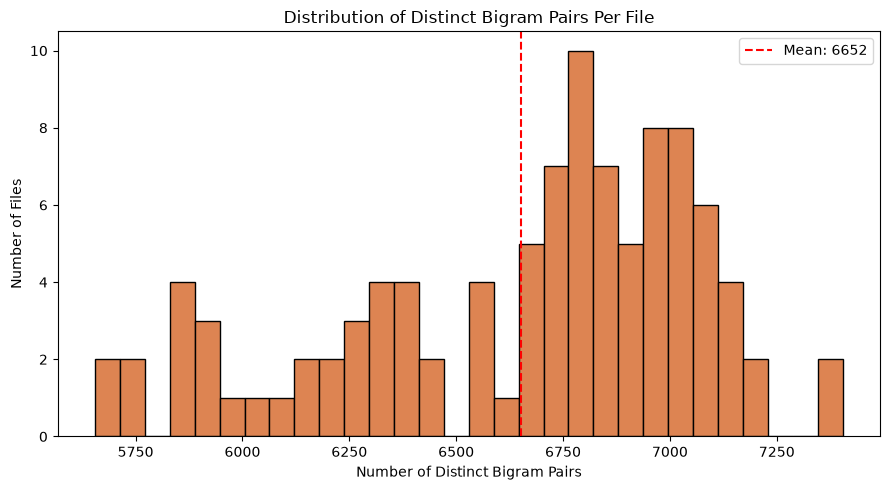

In [15]:
# Plot 3 - How many distinct bigram pairs each file uses
# A file that uses very few distinct pairs has highly repetitive behaviour
# A file with many distinct pairs has more varied instruction flow
# This is a per-file complexity signal which is useful for anomaly detection context
per_file_nnz = np.diff(bigram_matrix.indptr)  # nnz per row = distinct pairs per file

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(per_file_nnz, bins=30, color="#DD8452", edgecolor="black")

ax.set_title("Distribution of Distinct Bigram Pairs Per File")
ax.set_xlabel("Number of Distinct Bigram Pairs")
ax.set_ylabel("Number of Files")
ax.axvline(per_file_nnz.mean(), color="red", 
            linestyle = "--", label=f"Mean: {per_file_nnz.mean():.0f}")
ax.legend()

plt.tight_layout()
plt.show()

----
## 3. Markov Transition Matrices

A first order Markov model turns the bigram counts into transition probabilities, the chance that opcode B follows opcode A. This is closely related to the bigram features but not the same. The transition matrix is framed as probabilities rather than raw counts.

Each file produces a `vocab_size` vs `vocab_size` matrix. Flattened, that is around 82,000 values per file. These are dense per file (unlike n-grams the transition matrix is naturally a fixed square shape), so they are stored as a dense feature matrix, one flattened row per file.

In [16]:
markov_rows = []

print(f"Building Markov Transition Features for {len(npy_files)} files...\n")
t0 = time.time()

for i, path in enumerate(npy_files, 1):
    array = load_encoded_trace(path, mmap=True)

    # Row normalized transition matrix then flatten to a single feature row
    transition = markov_transition_matrix(array, vocab_size)
    markov_rows.append(transition.flatten())

    if i % 25 == 0 or i == len(npy_files):
        print(f"  [{i:>3}/{len(npy_files)}]  elapsed: {(time.time()-t0)/60:.1f} min")

# Stored as float32 to reduce the size vs float64 which is good enough for probabilities
markov_matrix = np.vstack(markov_rows).astype(np.float32)
print(f"\nMarkov feature matrix shape: {markov_matrix.shape}")

Building Markov Transition Features for 100 files...

  [ 25/100]  elapsed: 1.6 min
  [ 50/100]  elapsed: 3.3 min
  [ 75/100]  elapsed: 4.8 min
  [100/100]  elapsed: 6.4 min

Markov feature matrix shape: (100, 82369)


In [17]:
# Saved as a compressed .npz to keep around 82k column float matrix manageable
np.savez_compressed(
    os.path.join(FEATURES_DIR, "markov_features.npz"),
    features = markov_matrix,
    sample_ids = np.array(sample_ids)
)
print("markov_features.npz file saved!")

markov_features.npz file saved!


### Visualize a Markov Transition Matrix

The transition matrix for a single file which showing the probability of one opcode following another. Brighter cells are more likely transitions. This is a per-file behavioural fingerprint the anomaly models will learn from.

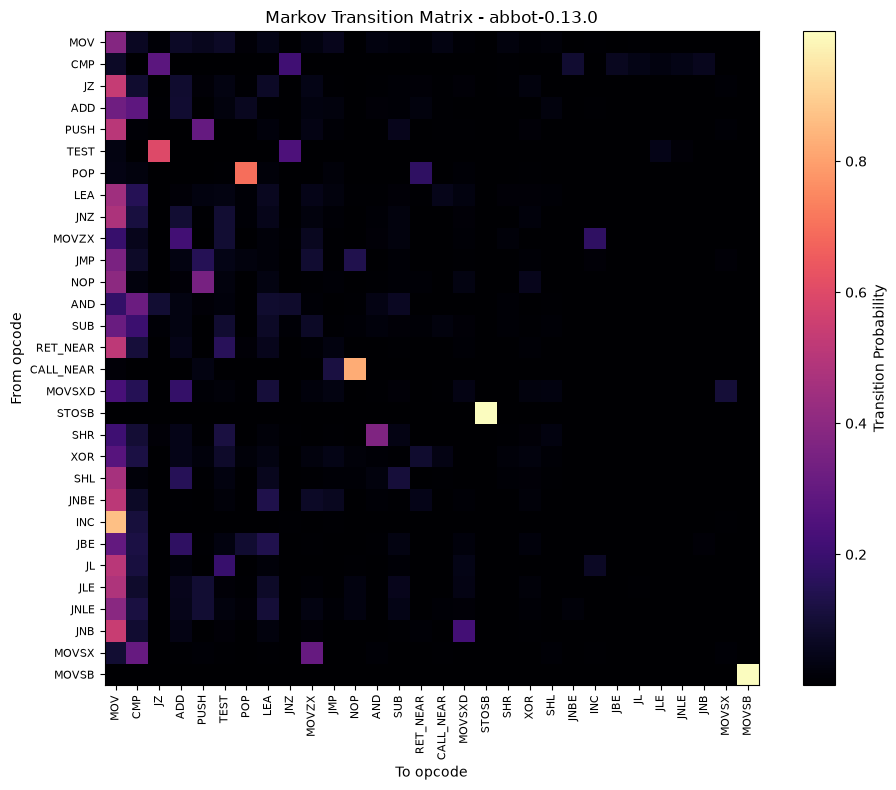

In [18]:
# Reshape one file flattened Markov row back into a vocab_size vs vocab_size matrix
sample_index = 0
sample_name = sample_ids[sample_index]
transition = markov_matrix[sample_index].reshape(vocab_size, vocab_size)

# Show only the top opcodes so the labels stay readable
top_idx = [vocab.index(op) for op in top_opcodes[:30]]
sub_matrix = transition[np.ix_(top_idx, top_idx)]
sub_labels = [vocab[i] for i in top_idx]

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(sub_matrix, cmap="magma")

ax.set_xticks(range(len(sub_labels)))
ax.set_xticklabels(sub_labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(sub_labels)))
ax.set_yticklabels(sub_labels, fontsize=8)

ax.set_title(f"Markov Transition Matrix - {sample_name}")
ax.set_xlabel("To opcode")
ax.set_ylabel("From opcode")
fig.colorbar(im, ax=ax, label = "Transition Probability")

plt.tight_layout()
plt.show()

----
## 4. Sliding Window Phase Features

This one keeps a time dimension by sliding a fixed-size window across each trace and computing a frequency vector per window. Plotting how
these window vectors change over the run shows the execution phases (startup, I/O heavy, compute heavy).

In [19]:
# opcodes per window
WINDOW_SIZE = 100_000

# Directory to store sliding window features files
SLIDING_DIR = os.path.join(FEATURES_DIR, "sliding_windows")
os.makedirs(SLIDING_DIR, exist_ok=True)

window_summary = []

print(f"Building Sliding Window features (window = {WINDOW_SIZE:,}) for {len(npy_files)} files...\n")
t0 = time.time()

# Process each file and save its sliding window features separately
for i, path in enumerate(npy_files, 1):
    array = load_encoded_trace(path, mmap=True)
    sample = os.path.basename(path).replace(".npy", "")

    # One normalized frequency vector per window - shape (n_windows, vocab_size)
    windows = sliding_window_features(array, vocab_size, window_size=WINDOW_SIZE)

    # Save each file window matrix separately because the row count can vary
    np.save(os.path.join(SLIDING_DIR, f"{sample}.npy"), windows.astype(np.float32))
    window_summary.append({"sample_id": sample, "n_windows": windows.shape[0]})

    if i % 20 == 0 or i == len(npy_files):
        print(f"  [{i:>3}/{len(npy_files)}]  elapsed: {(time.time()-t0)/60:.1f} min")

df_windows = pd.DataFrame(window_summary)
print(f"\nWindow Count Summary:")
print(df_windows["n_windows"].describe())

Building Sliding Window features (window = 100,000) for 100 files...

  [ 20/100]  elapsed: 0.4 min
  [ 40/100]  elapsed: 0.8 min
  [ 60/100]  elapsed: 1.1 min
  [ 80/100]  elapsed: 1.5 min
  [100/100]  elapsed: 1.9 min

Window Count Summary:
count     100.000000
mean     2158.180000
std       451.938527
min      1328.000000
25%      1731.500000
50%      2457.000000
75%      2522.500000
max      2736.000000
Name: n_windows, dtype: float64


In [20]:
df_windows.to_csv(os.path.join(FEATURES_DIR, "sliding_window_summary.csv"), index=False)
print("sliding_window_summary.csv file saved!")
print(f"Per-file window matrices saved in: {SLIDING_DIR}/")

sliding_window_summary.csv file saved!
Per-file window matrices saved in: ../sandbox/data-e4/features\sliding_windows/


### Visualize Execution Phase Timeline
Each column is one window in execution order, each row is an opcode, and the colour shows how much of that window each opcode makes up. 

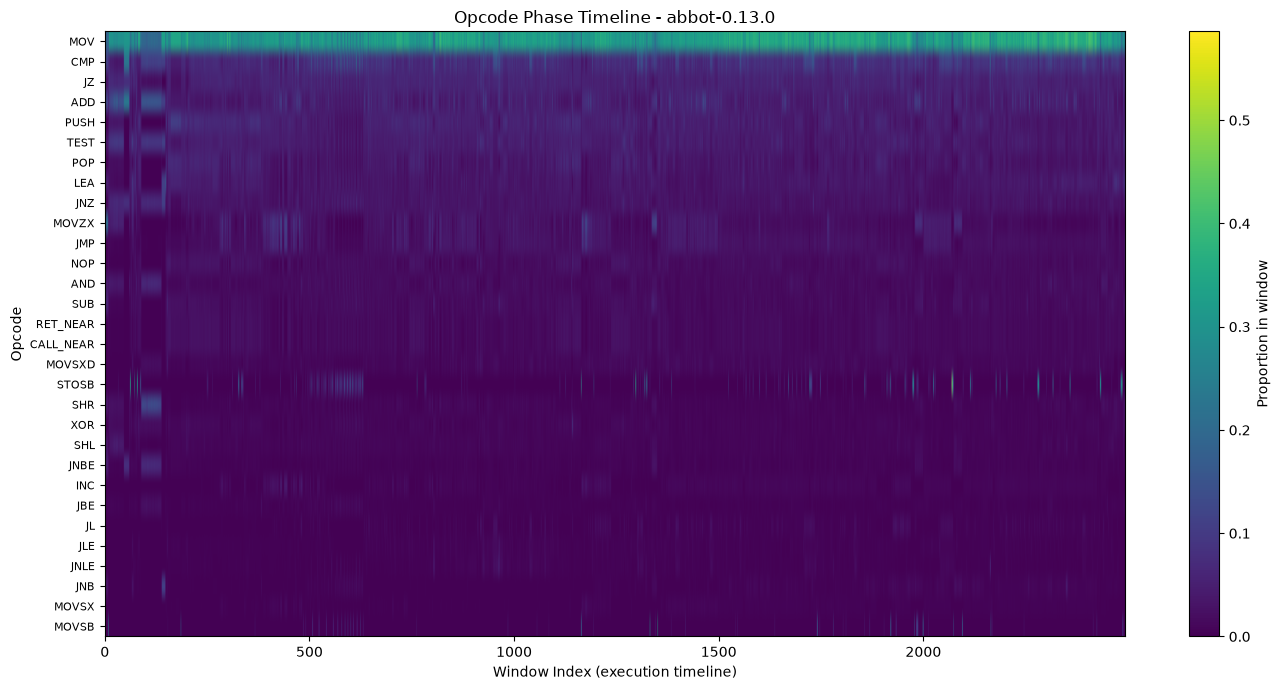

In [21]:
# Load one file window matrix and show it as a phase of the timeline
sample_name = sample_ids[0]
windows = np.load(os.path.join(SLIDING_DIR, f"{sample_name}.npy"))

# Show only the top opcodes as rows so the phases are visible
top_idx = [vocab.index(op) for op in top_opcodes[:30]]

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(windows[:, top_idx].T, aspect="auto", cmap = "viridis")

ax.set_xlabel("Window Index (execution timeline)")
ax.set_ylabel("Opcode")
ax.set_yticks(range(len(top_idx)))
ax.set_yticklabels([vocab[i] for i in top_idx], fontsize=8)
ax.set_title(f"Opcode Phase Timeline - {sample_name}")
fig.colorbar(im, ax=ax, label = "Proportion in window")

plt.tight_layout()
plt.show()